# Setup

In [1]:
import os
import numpy as np
import pandas as pd

import plotly.express as px

In [2]:
DOWNLOADED_SUMMARY = '/mnt/craig/pan_phylon/S_pyogenes/metadata/filtered_downloaded_species_summary.csv'
DOWNLOADED_METADATA = '/mnt/craig/pan_phylon/S_pyogenes/metadata/filtered_downloaded_species_metadata.csv'

In [3]:
downloaded_summary = pd.read_csv(DOWNLOADED_SUMMARY, index_col=0, dtype='object')
downloaded_metadata = pd.read_csv(DOWNLOADED_METADATA, index_col=0, dtype='object')

display(
    downloaded_summary.shape,
    downloaded_summary.head()
)

(281, 20)

,genome_id,genome_name,taxon_id,genome_status,genome_length,gc_content,contig_l50,contig_n50,chromosomes,plasmids,contigs,patric_cds,refseq_cds,trna,rrnacoarse_consistency,fine_consistency,checkm_completeness,checkm_contamination,genome_qualitydate_created,date_modified
0,1010840.4,Streptococcus pyogenes MGAS1882,1010840,Complete,1781029,38.0,1,1,1,0,1,1727,0,57,NaN,99.5,100.0,0.0,NaN,2015-03-16T03:17:09.594Z
1,1048264.3,Streptococcus pyogenes HKU QMH11M0907901,1048264,Complete,1908100,38.45,1,1,1,NaN,1,1909,1865,67,NaN,99.9,100.0,0.9,NaN,2016-01-17T15:29:01.552Z
2,1150773.3,Streptococcus pyogenes JRS4,1150773,Complete,1811968,38.63,1,1,1,NaN,1,1811,1671,67,NaN,99.8,100.0,0.0,NaN,2016-01-17T16:03:54.402Z
3,1150773.4,Streptococcus pyogenes JRS4,1150773,Complete,1811124,38.64,1,1,1,NaN,1,1886,1890,66,NaN,99.9,100.0,0.0,NaN,2016-03-01T06:31:23.641Z
4,1207470.4,Streptococcus pyogenes M1 476,1207470,Complete,1831079,38.5,1,1,1,0,1,1929,1849,57,NaN,97.9,100.0,5.0,NaN,2015-03-16T03:17:09.594Z


# De-duplicate entries

## Ensure `biosample_accession` is unique & drop duplicates

In [4]:
downloaded_metadata = downloaded_metadata.drop_duplicates(subset=['biosample_accession'])

display(
    downloaded_metadata.shape,
    downloaded_metadata.head()
)

(281, 66)

,genome_id,genome_name,organism_name,taxon_id,genome_status,strain,serovar,biovar,pathovar,mlst,...,motility,sporulation,temperature_range,optimal_temperature,salinity,oxygen_requirement,habitat,disease,comments,additional_metadata
0,1010840.4,Streptococcus pyogenes MGAS1882,Streptococcus pyogenes MGAS1882,1010840,Complete,MGAS1882,NaN,NaN,NaN,MLST.Streptococcus_pyogenes.172,...,NaN,NaN,NaN,NaN,NaN,NaN,Host,NaN,-,NaN
1,1048264.3,Streptococcus pyogenes HKU QMH11M0907901,NaN,1048264,Complete,HKU QMH11M0907901,NaN,NaN,NaN,MLST.Streptococcus_pyogenes.36,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Clinical use of next generation sequencing for...,NaN
2,1150773.3,Streptococcus pyogenes JRS4,NaN,1150773,Complete,JRS4,serovar emm6,NaN,NaN,MLST.Streptococcus_pyogenes.37,...,NaN,NaN,NaN,C,NaN,NaN,NaN,NaN,We report the complete genome assemblies of th...,collected_by:Rockefeller University Lancefield...
3,1150773.4,Streptococcus pyogenes JRS4,NaN,1150773,Complete,JRS4,NaN,NaN,NaN,MLST.Streptococcus_pyogenes.37,...,No,NaN,NaN,NaN,NaN,NaN,NaN,Pharyngitis,Complete genome sequence of the highly invasiv...,NaN
4,1207470.4,Streptococcus pyogenes M1 476,Streptococcus pyogenes M1 476,1207470,Complete,476,NaN,NaN,NaN,MLST.Streptococcus_pyogenes.28,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Toxic shock syndrome,We report the completely annotated genome sequ...,NaN


## (Optional) Go through and remove any empty or mostly empty columns

In [5]:
# mostly_empty_cols = pd.DataFrame(index=downloaded_metadata.columns, columns=['num_NA'])

# for col in downloaded_metadata.columns:
#     mostly_empty_cols.at[col, 'num_NA'] = downloaded_metadata[col].isna().sum()


# # Drop anything for which over 50% of the metadata entries are N/A
# px.histogram(mostly_empty_cols, x='num_NA', nbins=100)

In [6]:
# cutoff_cols_NA =  downloaded_metadata.shape[0]/2
# cond = mostly_empty_cols.num_NA < cutoff_cols_NA

# mostly_full_cols = mostly_empty_cols[cond]
# mostly_full_cols.loc['plasmids', 'num_NA'] = mostly_empty_cols.loc['plasmids', 'num_NA']

# mostly_full_cols

In [7]:
#scrubbed_metadata = downloaded_metadata[mostly_full_cols.index]
scrubbed_metadata = downloaded_metadata.copy()

display(
    scrubbed_metadata.shape,
    scrubbed_metadata.head()
)

(281, 66)

,genome_id,genome_name,organism_name,taxon_id,genome_status,strain,serovar,biovar,pathovar,mlst,...,motility,sporulation,temperature_range,optimal_temperature,salinity,oxygen_requirement,habitat,disease,comments,additional_metadata
0,1010840.4,Streptococcus pyogenes MGAS1882,Streptococcus pyogenes MGAS1882,1010840,Complete,MGAS1882,NaN,NaN,NaN,MLST.Streptococcus_pyogenes.172,...,NaN,NaN,NaN,NaN,NaN,NaN,Host,NaN,-,NaN
1,1048264.3,Streptococcus pyogenes HKU QMH11M0907901,NaN,1048264,Complete,HKU QMH11M0907901,NaN,NaN,NaN,MLST.Streptococcus_pyogenes.36,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Clinical use of next generation sequencing for...,NaN
2,1150773.3,Streptococcus pyogenes JRS4,NaN,1150773,Complete,JRS4,serovar emm6,NaN,NaN,MLST.Streptococcus_pyogenes.37,...,NaN,NaN,NaN,C,NaN,NaN,NaN,NaN,We report the complete genome assemblies of th...,collected_by:Rockefeller University Lancefield...
3,1150773.4,Streptococcus pyogenes JRS4,NaN,1150773,Complete,JRS4,NaN,NaN,NaN,MLST.Streptococcus_pyogenes.37,...,No,NaN,NaN,NaN,NaN,NaN,NaN,Pharyngitis,Complete genome sequence of the highly invasiv...,NaN
4,1207470.4,Streptococcus pyogenes M1 476,Streptococcus pyogenes M1 476,1207470,Complete,476,NaN,NaN,NaN,MLST.Streptococcus_pyogenes.28,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Toxic shock syndrome,We report the completely annotated genome sequ...,NaN


In [8]:
scrubbed_summary = downloaded_summary.copy()

common_genomes = sorted(set(scrubbed_metadata['genome_id']).intersection(set(scrubbed_summary['genome_id'])))
scrubbed_summary = scrubbed_summary.set_index('genome_id').loc[common_genomes].reset_index()

display(
    scrubbed_summary.shape,
    scrubbed_summary.head()
)

(281, 20)

,genome_id,genome_name,taxon_id,genome_status,genome_length,gc_content,contig_l50,contig_n50,chromosomes,plasmids,contigs,patric_cds,refseq_cds,trna,rrnacoarse_consistency,fine_consistency,checkm_completeness,checkm_contamination,genome_qualitydate_created,date_modified
0,1010840.4,Streptococcus pyogenes MGAS1882,1010840,Complete,1781029,38.0,1,1,1,0,1,1727,0,57,NaN,99.5,100.0,0.0,NaN,2015-03-16T03:17:09.594Z
1,1048264.3,Streptococcus pyogenes HKU QMH11M0907901,1048264,Complete,1908100,38.45,1,1,1,NaN,1,1909,1865,67,NaN,99.9,100.0,0.9,NaN,2016-01-17T15:29:01.552Z
2,1150773.3,Streptococcus pyogenes JRS4,1150773,Complete,1811968,38.63,1,1,1,NaN,1,1811,1671,67,NaN,99.8,100.0,0.0,NaN,2016-01-17T16:03:54.402Z
3,1150773.4,Streptococcus pyogenes JRS4,1150773,Complete,1811124,38.64,1,1,1,NaN,1,1886,1890,66,NaN,99.9,100.0,0.0,NaN,2016-03-01T06:31:23.641Z
4,1207470.4,Streptococcus pyogenes M1 476,1207470,Complete,1831079,38.5,1,1,1,0,1,1929,1849,57,NaN,97.9,100.0,5.0,NaN,2015-03-16T03:17:09.594Z


# Save cleaned summary & metadata files

In [9]:
filepath = DOWNLOADED_METADATA.split('filtered_downloaded_species_metadata')[0]
filepath = os.path.join(filepath, 'scrubbed_species_metadata.csv')

filepath

'/mnt/craig/pan_phylon/S_pyogenes/metadata/scrubbed_species_metadata.csv'

In [10]:
scrubbed_metadata.to_csv(filepath)

In [11]:
filepath = DOWNLOADED_SUMMARY.split('filtered_downloaded_species_summary')[0]
filepath = os.path.join(filepath, 'scrubbed_species_summary.csv')

filepath

'/mnt/craig/pan_phylon/S_pyogenes/metadata/scrubbed_species_summary.csv'

In [12]:
scrubbed_summary.to_csv(filepath)

In [13]:
downloaded_summary.shape[0] - scrubbed_summary.shape[0] # Number of genomes filtered during de-duplication

0

In [15]:
# Ensure reference strain still exists after scrubbing
display(
    scrubbed_metadata.set_index('genome_id').loc['1314.739'],
    scrubbed_summary.set_index('genome_id').loc['1314.739']
)

genome_name                      Streptococcus pyogenes strain NCTC12064
organism_name                                                        NaN
taxon_id                                                            1314
genome_status                                                   Complete
strain                                                         NCTC12064
                                             ...                        
oxygen_requirement                                                   NaN
habitat                                                              NaN
disease                                                              NaN
comments               http://www.sanger.ac.uk/resources/downloads/ba...
additional_metadata                                                  NaN
Name: 1314.739, Length: 65, dtype: object

genome_name                   Streptococcus pyogenes strain NCTC12064
taxon_id                                                         1314
genome_status                                                Complete
genome_length                                                 1746380
gc_content                                                  38.549114
contig_l50                                                          1
contig_n50                                                          1
chromosomes                                                         1
plasmids                                                          NaN
contigs                                                             1
patric_cds                                                       1704
refseq_cds                                                       1630
trna                                                               67
rrnacoarse_consistency                                            NaN
fine_consistency    

In [16]:
scrubbed_summary.checkm_completeness.min()

'100.0'

In [34]:
scrubbed_summary.checkm_completeness.isna().sum()

0

In [18]:
scrubbed_summary.checkm_contamination.max()

'9.4'

In [35]:
scrubbed_summary.checkm_contamination.isna().sum()

0

<Axes: >

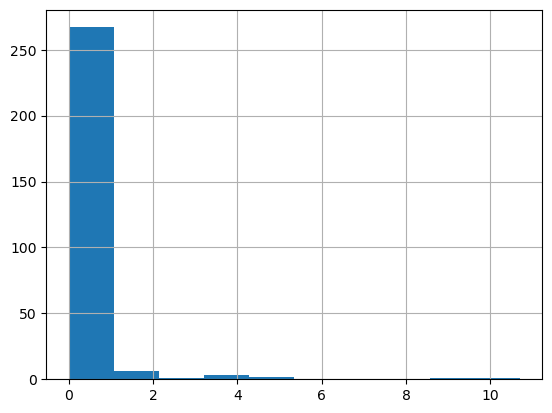

In [20]:
scrubbed_summary.checkm_contamination.astype('float').hist()

In [32]:
pd.read_csv('/mnt/craig/pan_phylon/S_pyogenes/raw/checkm_output/checkm_qa_filtered.tsv', sep='\t').columns

Index(['Bin Id', 'Marker lineage', '# genomes', '# markers', '# marker sets',
       'Completeness', 'Contamination', 'Strain heterogeneity',
       'Genome size (bp)', '# ambiguous bases', '# scaffolds', '# contigs',
       'N50 (scaffolds)', 'N50 (contigs)', 'Mean scaffold length (bp)',
       'Mean contig length (bp)', 'Longest scaffold (bp)',
       'Longest contig (bp)', 'GC', 'GC std (scaffolds > 1kbp)',
       'Coding density', 'Translation table', '# predicted genes', '0', '1',
       '2', '3', '4', '5+', 'checkm_pass'],
      dtype='object')